In [1]:
print("Hello! Diabetes Health Indicator Analysis")


Hello! Diabetes Health Indicator Analysis


In [2]:
import pandas as pd

df = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
import pandas as pd

In [5]:
df = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [7]:
df.shape

(253680, 22)

In [8]:
df.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [10]:
df["Diabetes_012"].value_counts().sort_index()

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

In [11]:
diabetes_percentage = df["Diabetes_012"].value_counts(normalize=True).sort_index() * 100

print(diabetes_percentage)

Diabetes_012
0.0    84.241170
1.0     1.825528
2.0    13.933302
Name: proportion, dtype: float64


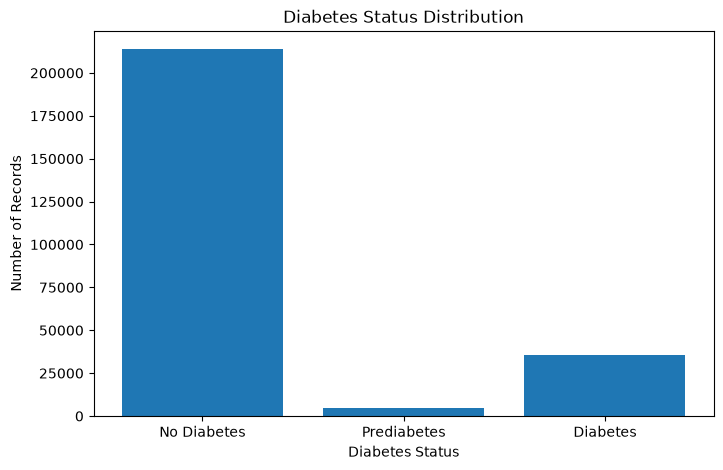

In [12]:
import matplotlib.pyplot as plt

counts = df["Diabetes_012"].value_counts().sort_index()

labels = ["No Diabetes", "Prediabetes", "Diabetes"]

plt.figure(figsize=(8, 5))
plt.bar(labels, counts)

plt.title("Diabetes Status Distribution")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Records")

plt.show()

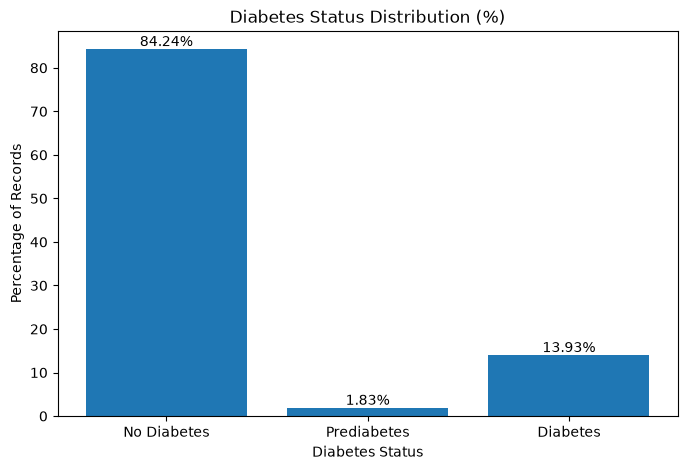

In [13]:
import matplotlib.pyplot as plt

percentage = df["Diabetes_012"].value_counts(normalize=True).sort_index() * 100

labels = ["No Diabetes", "Prediabetes", "Diabetes"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, percentage)

plt.title("Diabetes Status Distribution (%)")
plt.xlabel("Diabetes Status")
plt.ylabel("Percentage of Records")

for bar, value in zip(bars, percentage):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()

In [14]:
bp_diabetes = pd.crosstab(
    df["HighBP"],
    df["Diabetes_012"],
    normalize="index"
) * 100

bp_diabetes

Diabetes_012,0.0,1.0,2.0
HighBP,,,
0.0,92.778786,1.186046,6.035167
1.0,72.877634,2.676676,24.445690


In [15]:
bp_diabetes.index = ["No High BP", "High BP"]
bp_diabetes.columns = ["No Diabetes", "Prediabetes", "Diabetes"]

bp_diabetes

,No Diabetes,Prediabetes,Diabetes
No High BP,92.778786,1.186046,6.035167
High BP,72.877634,2.676676,24.445690


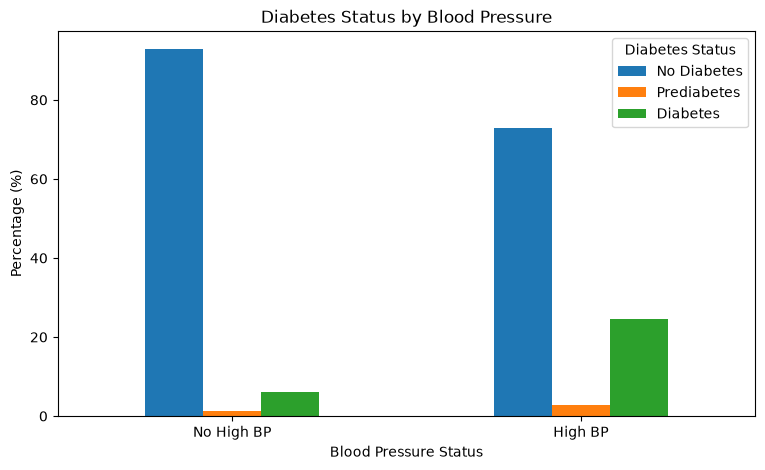

In [16]:
bp_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Blood Pressure")
plt.xlabel("Blood Pressure Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [17]:
chol_diabetes = pd.crosstab(
    df["HighChol"],
    df["Diabetes_012"],
    normalize="index"
) * 100

chol_diabetes


Diabetes_012,0.0,1.0,2.0
HighChol,,,
0.0,90.816557,1.202007,7.981436
1.0,75.312991,2.672157,22.014853


In [18]:
chol_diabetes.index = ["No High Cholesterol", "High Cholesterol"]
chol_diabetes.columns = ["No Diabetes", "Prediabetes", "Diabetes"]

chol_diabetes

,No Diabetes,Prediabetes,Diabetes
No High Cholesterol,90.816557,1.202007,7.981436
High Cholesterol,75.312991,2.672157,22.014853


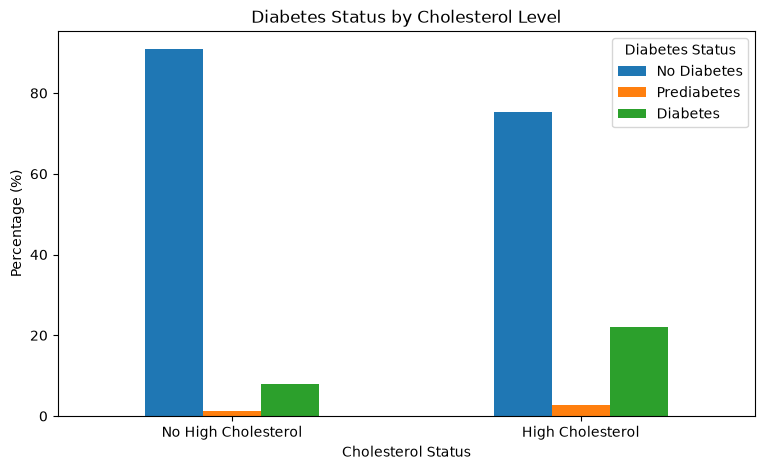

In [19]:
chol_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Cholesterol Level")
plt.xlabel("Cholesterol Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [20]:
df["BMI"].describe()

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64

In [21]:
df.groupby("Diabetes_012")["BMI"].mean()

Diabetes_012
0.0    27.742521
1.0    30.724466
2.0    31.944011
Name: BMI, dtype: float64

In [22]:
bmi_by_diabetes = df.groupby("Diabetes_012")["BMI"].agg(
    ["count", "mean", "median", "min", "max"]
)

bmi_by_diabetes.index = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

bmi_by_diabetes

,count,mean,median,min,max
No Diabetes,213703,27.742521,27.0,12.0,98.0
Prediabetes,4631,30.724466,30.0,13.0,96.0
Diabetes,35346,31.944011,31.0,13.0,98.0


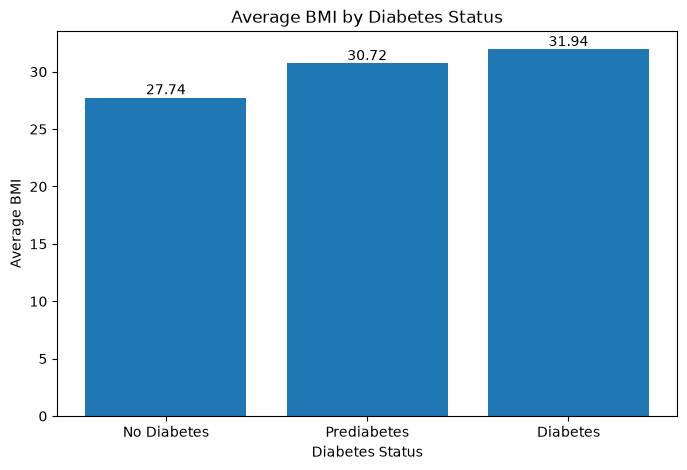

In [23]:
bmi_means = df.groupby("Diabetes_012")["BMI"].mean()

labels = ["No Diabetes", "Prediabetes", "Diabetes"]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, bmi_means)

plt.title("Average BMI by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Average BMI")

for bar, value in zip(bars, bmi_means):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.show()

In [2]:
activity_diabetes = pd.crosstab(
    df["PhysActivity"],
    df["Diabetes_012"],
    normalize="index"
) * 100

activity_diabetes

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.shape

(253680, 22)

In [6]:
activity_diabetes = pd.crosstab(
    df["PhysActivity"],
    df["Diabetes_012"],
    normalize="index"
) * 100

activity_diabetes

Diabetes_012,0.0,1.0,2.0
PhysActivity,,,
0.0,76.444301,2.410946,21.144754
1.0,86.750208,1.637140,11.612651


In [7]:
activity_diabetes.index = [
    "No Physical Activity",
    "Physical Activity"
]

activity_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

activity_diabetes

,No Diabetes,Prediabetes,Diabetes
No Physical Activity,76.444301,2.410946,21.144754
Physical Activity,86.750208,1.637140,11.612651


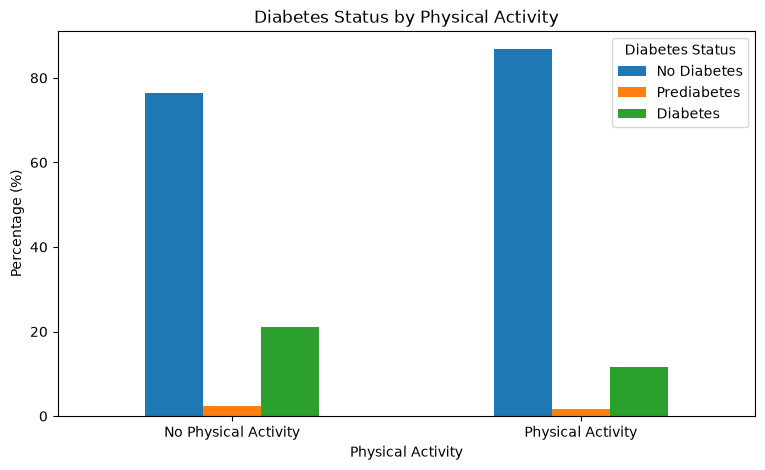

In [8]:
activity_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Physical Activity")
plt.xlabel("Physical Activity")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [9]:
df["GenHlth"].value_counts().sort_index()

GenHlth
1.0    45299
2.0    89084
3.0    75646
4.0    31570
5.0    12081
Name: count, dtype: int64

In [10]:
health_diabetes = pd.crosstab(
    df["GenHlth"],
    df["Diabetes_012"],
    normalize="index"
) * 100

health_diabetes

Diabetes_012,0.0,1.0,2.0
GenHlth,,,
1.0,96.792424,0.690964,2.516612
2.0,91.474339,1.362759,7.162902
3.0,79.926235,2.284324,17.789440
4.0,65.742794,3.246753,31.010453
5.0,59.200397,2.905389,37.894214


In [11]:
health_diabetes.index = [
    "Excellent",
    "Very Good",
    "Good",
    "Fair",
    "Poor"
]

health_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

health_diabetes

,No Diabetes,Prediabetes,Diabetes
Excellent,96.792424,0.690964,2.516612
Very Good,91.474339,1.362759,7.162902
Good,79.926235,2.284324,17.789440
Fair,65.742794,3.246753,31.010453
Poor,59.200397,2.905389,37.894214


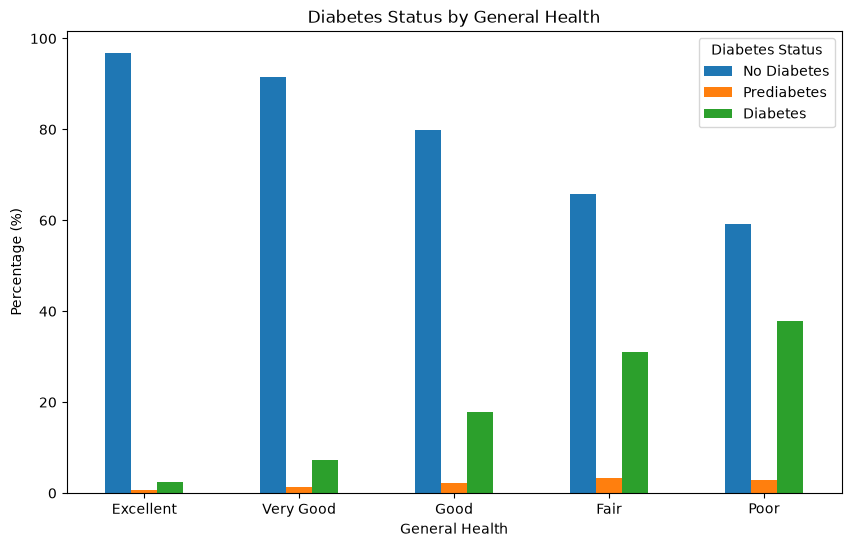

In [12]:
health_diabetes.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Diabetes Status by General Health")
plt.xlabel("General Health")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [13]:
df["Age"].value_counts().sort_index()

Age
1.0      5700
2.0      7598
3.0     11123
4.0     13823
5.0     16157
6.0     19819
7.0     26314
8.0     30832
9.0     33244
10.0    32194
11.0    23533
12.0    15980
13.0    17363
Name: count, dtype: int64

In [14]:
age_diabetes = pd.crosstab(
    df["Age"],
    df["Diabetes_012"],
    normalize="index"
) * 100

age_diabetes

Diabetes_012,0.0,1.0,2.0
Age,,,
1.0,98.263158,0.368421,1.368421
2.0,97.446696,0.710713,1.842590
3.0,96.529713,0.647307,2.822979
4.0,94.444043,1.027273,4.528684
5.0,92.486229,1.008851,6.504920
6.0,89.636208,1.574247,8.789545
7.0,86.676294,1.588508,11.735198
8.0,84.389595,1.783861,13.826544
9.0,80.643124,2.111659,17.245217


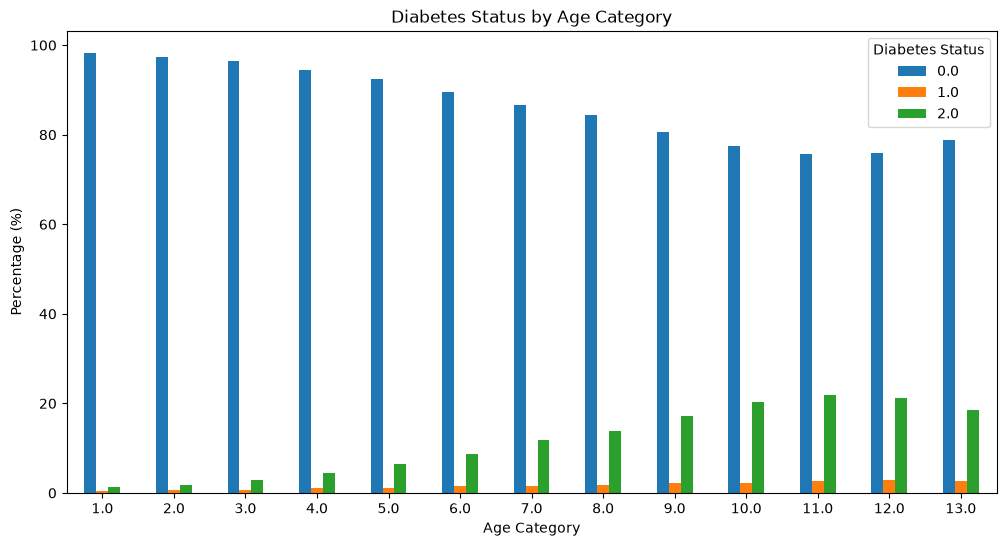

In [15]:
age_diabetes.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Diabetes Status by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [16]:
df["Age"].value_counts().sort_index()

Age
1.0      5700
2.0      7598
3.0     11123
4.0     13823
5.0     16157
6.0     19819
7.0     26314
8.0     30832
9.0     33244
10.0    32194
11.0    23533
12.0    15980
13.0    17363
Name: count, dtype: int64

In [17]:
age_diabetes = pd.crosstab(
    df["Age"],
    df["Diabetes_012"],
    normalize="index"
) * 100

age_diabetes

Diabetes_012,0.0,1.0,2.0
Age,,,
1.0,98.263158,0.368421,1.368421
2.0,97.446696,0.710713,1.842590
3.0,96.529713,0.647307,2.822979
4.0,94.444043,1.027273,4.528684
5.0,92.486229,1.008851,6.504920
6.0,89.636208,1.574247,8.789545
7.0,86.676294,1.588508,11.735198
8.0,84.389595,1.783861,13.826544
9.0,80.643124,2.111659,17.245217


In [18]:
age_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

age_diabetes

,No Diabetes,Prediabetes,Diabetes
Age,,,
1.0,98.263158,0.368421,1.368421
2.0,97.446696,0.710713,1.842590
3.0,96.529713,0.647307,2.822979
4.0,94.444043,1.027273,4.528684
5.0,92.486229,1.008851,6.504920
6.0,89.636208,1.574247,8.789545
7.0,86.676294,1.588508,11.735198
8.0,84.389595,1.783861,13.826544
9.0,80.643124,2.111659,17.245217


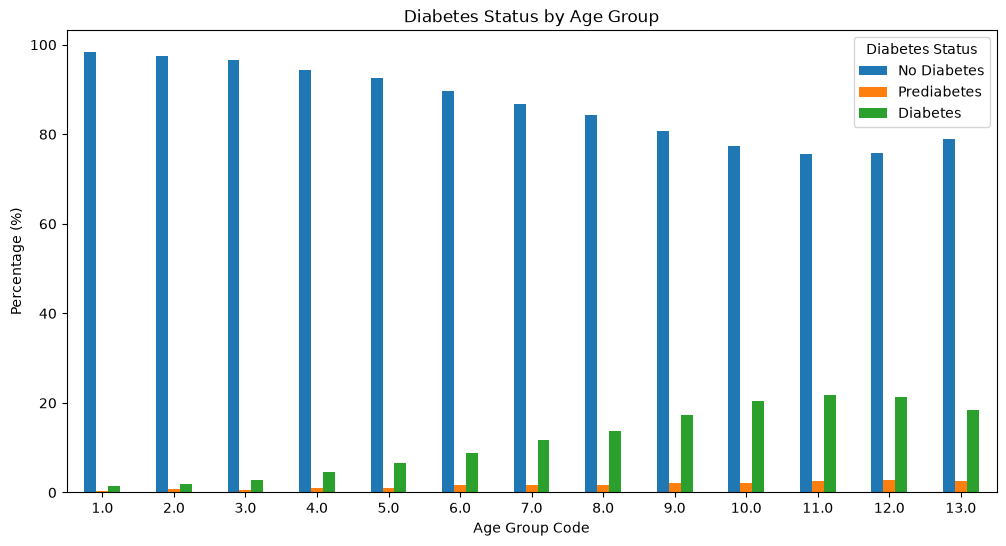

In [19]:
age_diabetes.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Diabetes Status by Age Group")
plt.xlabel("Age Group Code")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [20]:
smoker_diabetes = pd.crosstab(
    df["Smoker"],
    df["Diabetes_012"],
    normalize="index"
) * 100

smoker_diabetes

Diabetes_012,0.0,1.0,2.0
Smoker,,,
0.0,86.281742,1.662926,12.055332
1.0,81.677237,2.029834,16.292929


In [21]:
smoker_diabetes.index = [
    "Non-Smoker",
    "Smoker"
]

smoker_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

smoker_diabetes

,No Diabetes,Prediabetes,Diabetes
Non-Smoker,86.281742,1.662926,12.055332
Smoker,81.677237,2.029834,16.292929


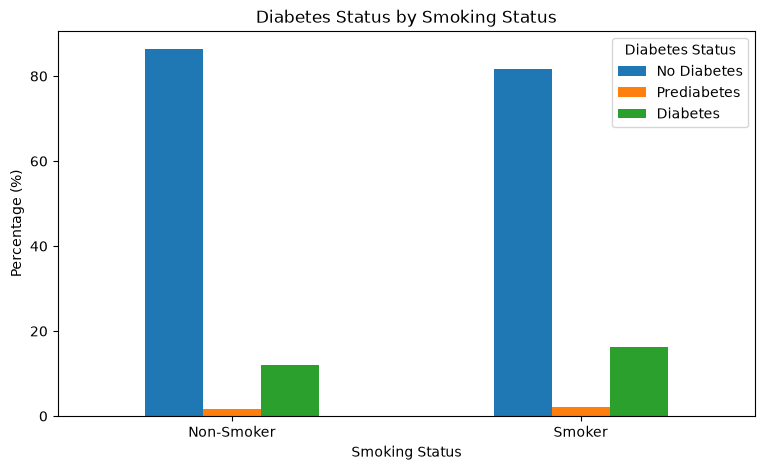

In [22]:
smoker_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [25]:
df["HeartDiseaseorAttack"]

0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
253675    0.0
253676    0.0
253677    0.0
253678    0.0
253679    1.0
Name: HeartDiseaseorAttack, Length: 253680, dtype: float64

In [26]:
df["HeartDiseaseorAttack"].value_counts()

HeartDiseaseorAttack
0.0    229787
1.0     23893
Name: count, dtype: int64

In [27]:
heart_diabetes = pd.crosstab(
    df["HeartDiseaseorAttack"],
    df["Diabetes_012"],
    normalize="index"
) * 100

heart_diabetes

Diabetes_012,0.0,1.0,2.0
HeartDiseaseorAttack,,,
0.0,86.319940,1.726381,11.953679
1.0,64.248943,2.779057,32.972000


In [28]:
heart_diabetes.index = [
    "No Heart Disease/Attack",
    "Heart Disease/Attack"
]

heart_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

heart_diabetes

,No Diabetes,Prediabetes,Diabetes
No Heart Disease/Attack,86.319940,1.726381,11.953679
Heart Disease/Attack,64.248943,2.779057,32.972000


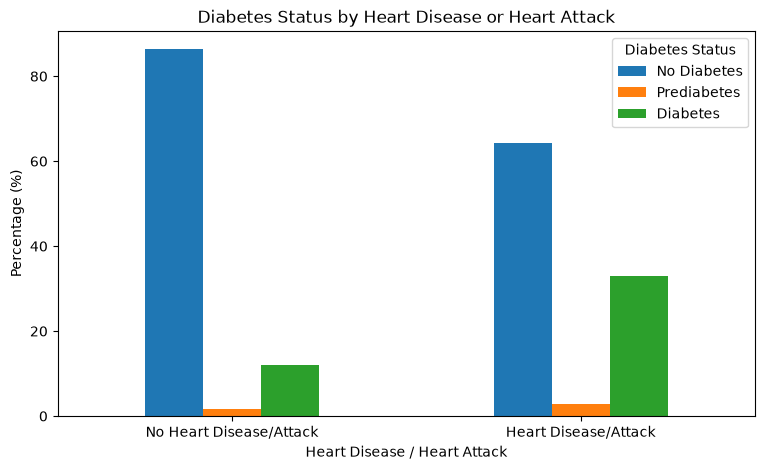

In [29]:
heart_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Heart Disease or Heart Attack")
plt.xlabel("Heart Disease / Heart Attack")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [30]:
df["Stroke"].value_counts()

Stroke
0.0    243388
1.0     10292
Name: count, dtype: int64

In [31]:
stroke_diabetes = pd.crosstab(
    df["Stroke"],
    df["Diabetes_012"],
    normalize="index"
) * 100

stroke_diabetes

Diabetes_012,0.0,1.0,2.0
Stroke,,,
0.0,85.026378,1.793844,13.179779
1.0,65.672367,2.574815,31.752818


In [32]:
stroke_diabetes.index = [
    "No Stroke",
    "Stroke"
]

stroke_diabetes.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

stroke_diabetes

,No Diabetes,Prediabetes,Diabetes
No Stroke,85.026378,1.793844,13.179779
Stroke,65.672367,2.574815,31.752818


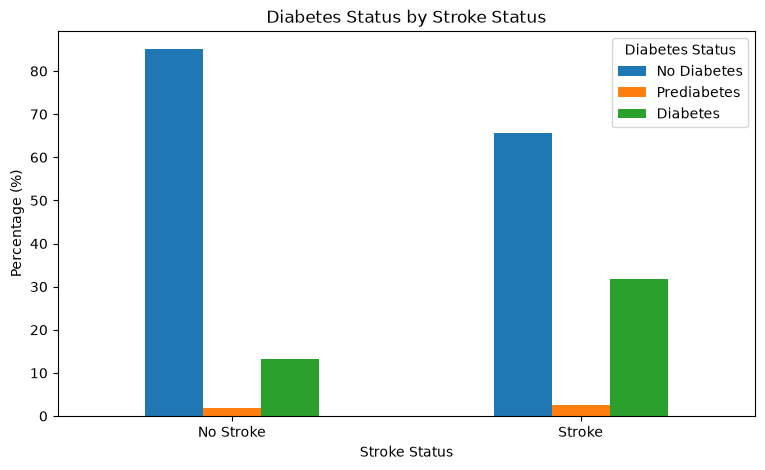

In [33]:
stroke_diabetes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetes Status by Stroke Status")
plt.xlabel("Stroke Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")

plt.show()

In [34]:
correlation = df.corr(numeric_only=True)
correlation

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
Diabetes_012,1.000000,0.271596,0.209085,0.067546,0.224379,0.062914,0.107179,0.180272,-0.121947,-0.042192,...,0.015410,0.035436,0.302587,0.073507,0.176287,0.224239,0.031040,0.185026,-0.130517,-0.171483
HighBP,0.271596,1.000000,0.298199,0.098508,0.213748,0.096991,0.129575,0.209361,-0.125267,-0.040555,...,0.038425,0.017358,0.300530,0.056456,0.161212,0.223618,0.052207,0.344452,-0.141358,-0.171235
HighChol,0.209085,0.298199,1.000000,0.085642,0.106722,0.091299,0.092620,0.180765,-0.078046,-0.040859,...,0.042230,0.013310,0.208426,0.062069,0.121751,0.144672,0.031205,0.272318,-0.070802,-0.085459
CholCheck,0.067546,0.098508,0.085642,1.000000,0.034495,-0.009929,0.024158,0.044206,0.004190,0.023849,...,0.117626,-0.058255,0.046589,-0.008366,0.031775,0.040585,-0.022115,0.090321,0.001510,0.014259
BMI,0.224379,0.213748,0.106722,0.034495,1.000000,0.013804,0.020153,0.052904,-0.147294,-0.087518,...,-0.018471,0.058206,0.239185,0.085310,0.121141,0.197078,0.042950,-0.036618,-0.103932,-0.100069
Smoker,0.062914,0.096991,0.091299,-0.009929,0.013804,1.000000,0.061173,0.114441,-0.087401,-0.077666,...,-0.023251,0.048946,0.163143,0.092196,0.116460,0.122463,0.093662,0.120641,-0.161955,-0.123937
Stroke,0.107179,0.129575,0.092620,0.024158,0.020153,0.061173,1.000000,0.203002,-0.069151,-0.013389,...,0.008776,0.034804,0.177942,0.070172,0.148944,0.176567,0.002978,0.126974,-0.076009,-0.128599
HeartDiseaseorAttack,0.180272,0.209361,0.180765,0.044206,0.052904,0.114441,0.203002,1.000000,-0.087299,-0.019790,...,0.018734,0.031000,0.258383,0.064621,0.181698,0.212709,0.086096,0.221618,-0.099600,-0.141011
PhysActivity,-0.121947,-0.125267,-0.078046,0.004190,-0.147294,-0.087401,-0.069151,-0.087299,1.000000,0.142756,...,0.035505,-0.061638,-0.266186,-0.125587,-0.219230,-0.253174,0.032482,-0.092511,0.199658,0.198539
Fruits,-0.042192,-0.040555,-0.040859,0.023849,-0.087518,-0.077666,-0.013389,-0.019790,0.142756,1.000000,...,0.031544,-0.044243,-0.103854,-0.068217,-0.044633,-0.048352,-0.091175,0.064547,0.110187,0.079929


In [35]:
diabetes_correlation = correlation["Diabetes_012"].sort_values(
    ascending=False
)

diabetes_correlation

Diabetes_012            1.000000
GenHlth                 0.302587
HighBP                  0.271596
BMI                     0.224379
DiffWalk                0.224239
HighChol                0.209085
Age                     0.185026
HeartDiseaseorAttack    0.180272
PhysHlth                0.176287
Stroke                  0.107179
MentHlth                0.073507
CholCheck               0.067546
Smoker                  0.062914
NoDocbcCost             0.035436
Sex                     0.031040
AnyHealthcare           0.015410
Fruits                 -0.042192
HvyAlcoholConsump      -0.057882
Veggies                -0.058972
PhysActivity           -0.121947
Education              -0.130517
Income                 -0.171483
Name: Diabetes_012, dtype: float64

In [36]:
diabetes_correlation = diabetes_correlation.drop("Diabetes_012")

diabetes_correlation

GenHlth                 0.302587
HighBP                  0.271596
BMI                     0.224379
DiffWalk                0.224239
HighChol                0.209085
Age                     0.185026
HeartDiseaseorAttack    0.180272
PhysHlth                0.176287
Stroke                  0.107179
MentHlth                0.073507
CholCheck               0.067546
Smoker                  0.062914
NoDocbcCost             0.035436
Sex                     0.031040
AnyHealthcare           0.015410
Fruits                 -0.042192
HvyAlcoholConsump      -0.057882
Veggies                -0.058972
PhysActivity           -0.121947
Education              -0.130517
Income                 -0.171483
Name: Diabetes_012, dtype: float64

In [37]:
top_correlations = (
    diabetes_correlation
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

top_correlations

GenHlth                 0.302587
HighBP                  0.271596
BMI                     0.224379
DiffWalk                0.224239
HighChol                0.209085
Age                     0.185026
HeartDiseaseorAttack    0.180272
PhysHlth                0.176287
Income                  0.171483
Education               0.130517
Name: Diabetes_012, dtype: float64

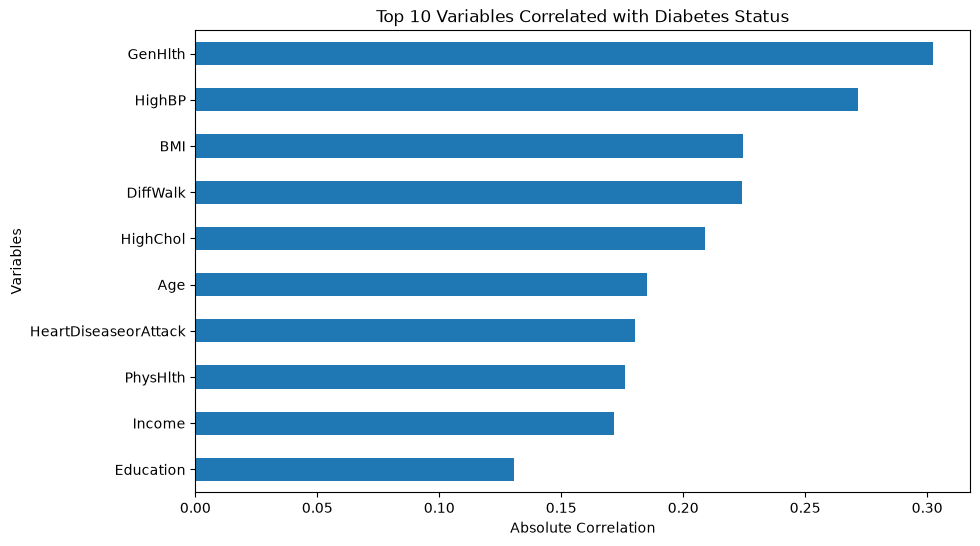

In [38]:
plt.figure(figsize=(10, 6))

top_correlations.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Variables Correlated with Diabetes Status")
plt.xlabel("Absolute Correlation")
plt.ylabel("Variables")

plt.show()

In [39]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [40]:
df.duplicated().sum()

np.int64(23899)

In [41]:
df["Diabetes_012"].value_counts().sort_index()

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

In [42]:
features = [
    "HighBP",
    "HighChol",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
]

X = df[features]
y = df["Diabetes_012"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (253680, 18)
y shape: (253680,)


In [43]:
from sklearn.model_selection import train_test_split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [45]:
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)

print("Training target  :", y_train.shape)
print("Testing target   :", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training features: (202944, 18)
Testing features : (50736, 18)
Training target  : (202944,)
Testing target   : (50736,)

Training class distribution:
Diabetes_012
0.0    0.842410
1.0    0.018256
2.0    0.139334
Name: proportion, dtype: float64

Testing class distribution:
Diabetes_012
0.0    0.842420
1.0    0.018251
2.0    0.139329
Name: proportion, dtype: float64


In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()

In [48]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
print("Original X_train shape:", X_train.shape)
print("Scaled X_train shape  :", X_train_scaled.shape)

print("Original X_test shape :", X_test.shape)
print("Scaled X_test shape   :", X_test_scaled.shape)

Original X_train shape: (202944, 18)
Scaled X_train shape  : (202944, 18)
Original X_test shape : (50736, 18)
Scaled X_test shape   : (50736, 18)


In [50]:
from sklearn.linear_model import LogisticRegression

In [51]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [52]:
logistic_model.fit(
    X_train_scaled,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [53]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

In [54]:
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("Accuracy: {:.2f}%".format(
    logistic_accuracy * 100
))

Accuracy: 84.56%


In [55]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ]
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.86      0.98      0.91     42741
 Prediabetes       0.00      0.00      0.00       926
    Diabetes       0.52      0.17      0.26      7069

    accuracy                           0.85     50736
   macro avg       0.46      0.38      0.39     50736
weighted avg       0.80      0.85      0.81     50736



c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `

In [56]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_logistic

array([[41687,     0,  1054],
       [  840,     0,    86],
       [ 5852,     0,  1217]])

In [57]:
from sklearn.tree import DecisionTreeClassifier

In [58]:
decision_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

In [59]:
decision_tree.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [60]:
y_pred_tree = decision_tree.predict(X_test)

In [61]:
tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print(
    "Decision Tree Accuracy: {:.2f}%".format(
        tree_accuracy * 100
    )
)

Decision Tree Accuracy: 84.52%


In [62]:
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ]
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.87      0.97      0.91     42741
 Prediabetes       0.30      0.00      0.01       926
    Diabetes       0.51      0.21      0.29      7069

    accuracy                           0.85     50736
   macro avg       0.56      0.39      0.40     50736
weighted avg       0.81      0.85      0.81     50736



In [63]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

cm_tree

array([[41420,     6,  1315],
       [  822,     3,   101],
       [ 5609,     1,  1459]])

In [64]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.845632,84.56
1,Decision Tree,0.845199,84.52


In [65]:
from sklearn.ensemble import RandomForestClassifier

In [66]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

In [67]:
random_forest.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [68]:
y_pred_rf = random_forest.predict(X_test)

In [69]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy: {:.2f}%".format(
        rf_accuracy * 100
    )
)

Random Forest Accuracy: 84.93%


In [70]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ]
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.86      0.99      0.92     42741
 Prediabetes       0.00      0.00      0.00       926
    Diabetes       0.58      0.14      0.22      7069

    accuracy                           0.85     50736
   macro avg       0.48      0.37      0.38     50736
weighted avg       0.80      0.85      0.80     50736



c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Sai Charan\OneDrive\Desktop\Diabetes_Health_Indicator_Analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `

In [71]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_rf

array([[42109,     0,   632],
       [  861,     0,    65],
       [ 6090,     0,   979]])

In [72]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        rf_accuracy
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.845632,84.56
1,Decision Tree,0.845199,84.52
2,Random Forest,0.849259,84.93


In [73]:
from sklearn.metrics import f1_score

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="macro"
)

tree_f1 = f1_score(
    y_test,
    y_pred_tree,
    average="macro"
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro"
)

f1_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Macro F1 Score": [
        logistic_f1,
        tree_f1,
        rf_f1
    ]
})

f1_comparison["Macro F1 (%)"] = (
    f1_comparison["Macro F1 Score"] * 100
).round(2)

f1_comparison

,Model,Macro F1 Score,Macro F1 (%)
0,Logistic Regression,0.391071,39.11
1,Decision Tree,0.404761,40.48
2,Random Forest,0.380432,38.04


In [74]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        logistic_accuracy * 100,
        tree_accuracy * 100,
        rf_accuracy * 100
    ],
    "Macro F1 (%)": [
        logistic_f1 * 100,
        tree_f1 * 100,
        rf_f1 * 100
    ]
})

final_model_comparison.round(2)

,Model,Accuracy (%),Macro F1 (%)
0,Logistic Regression,84.56,39.11
1,Decision Tree,84.52,40.48
2,Random Forest,84.93,38.04


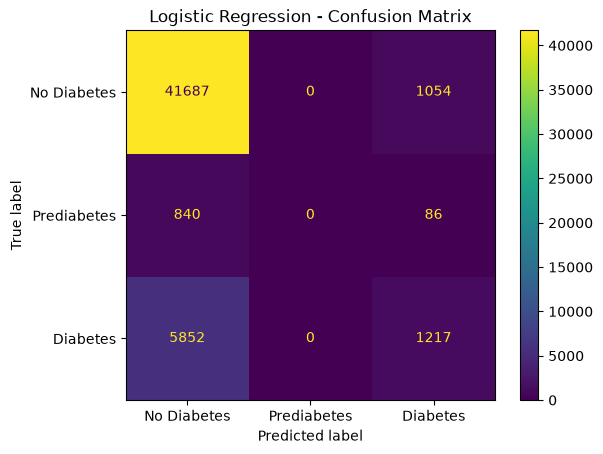

In [75]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    xticks_rotation=0
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

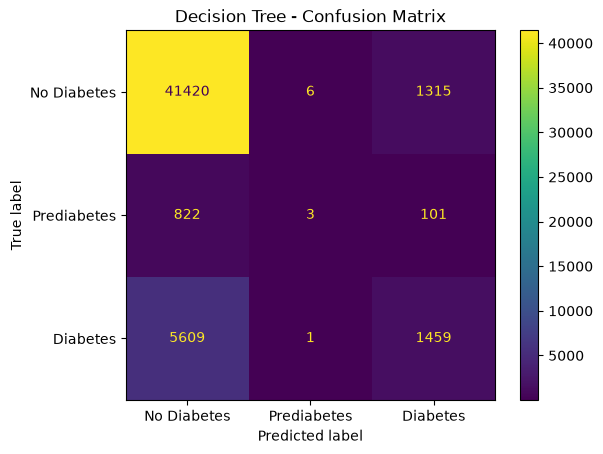

In [76]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    xticks_rotation=0
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

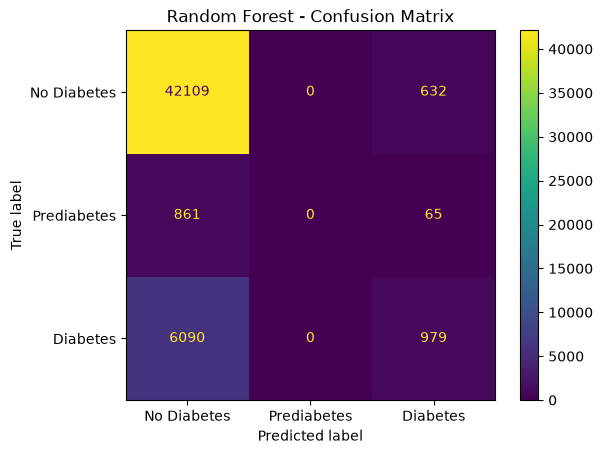

In [77]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ],
    xticks_rotation=0
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [78]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

models = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree),
    ("Random Forest", y_pred_rf)
]

for model_name, predictions in models:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

evaluation_df = pd.DataFrame(results)

evaluation_df.round(4)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.8456,0.4593,0.3825,0.3911
1,Decision Tree,0.8452,0.5577,0.3929,0.4048
2,Random Forest,0.8493,0.4808,0.3746,0.3804


In [79]:
for model_name, predictions in models:
    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )
    
    print("\n", model_name)
    print(
        "Diabetes Precision:",
        round(report["2.0"]["precision"], 4)
    )
    print(
        "Diabetes Recall:",
        round(report["2.0"]["recall"], 4)
    )
    print(
        "Diabetes F1:",
        round(report["2.0"]["f1-score"], 4)
    )


 Logistic Regression
Diabetes Precision: 0.5163
Diabetes Recall: 0.1722
Diabetes F1: 0.2582

 Decision Tree
Diabetes Precision: 0.5075
Diabetes Recall: 0.2064
Diabetes F1: 0.2934

 Random Forest
Diabetes Precision: 0.5841
Diabetes Recall: 0.1385
Diabetes F1: 0.2239


In [80]:
evaluation_df.to_csv(
    "model_evaluation.csv",
    index=False
)

print("Model evaluation saved successfully!")

Model evaluation saved successfully!


In [81]:
logistic_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [82]:
logistic_balanced.fit(
    X_train_scaled,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [83]:
y_pred_logistic_balanced = logistic_balanced.predict(
    X_test_scaled
)

In [84]:
print(
    classification_report(
        y_test,
        y_pred_logistic_balanced,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.95      0.66      0.78     42741
 Prediabetes       0.03      0.32      0.06       926
    Diabetes       0.35      0.59      0.44      7069

    accuracy                           0.65     50736
   macro avg       0.44      0.52      0.43     50736
weighted avg       0.85      0.65      0.72     50736



In [85]:
logistic_balanced_f1 = f1_score(
    y_test,
    y_pred_logistic_balanced,
    average="macro"
)

print(
    "Balanced Logistic Regression Macro F1: {:.2f}%".format(
        logistic_balanced_f1 * 100
    )
)

Balanced Logistic Regression Macro F1: 42.67%


In [86]:
random_forest_balanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [87]:
random_forest_balanced.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [88]:
y_pred_rf_balanced = random_forest_balanced.predict(
    X_test
)

In [89]:
print(
    classification_report(
        y_test,
        y_pred_rf_balanced,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.94      0.69      0.80     42741
 Prediabetes       0.03      0.14      0.05       926
    Diabetes       0.33      0.69      0.44      7069

    accuracy                           0.68     50736
   macro avg       0.43      0.51      0.43     50736
weighted avg       0.84      0.68      0.74     50736



In [90]:
rf_balanced_f1 = f1_score(
    y_test,
    y_pred_rf_balanced,
    average="macro"
)

print(
    "Balanced Random Forest Macro F1: {:.2f}%".format(
        rf_balanced_f1 * 100
    )
)

Balanced Random Forest Macro F1: 43.01%


In [91]:
balanced_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Balanced Random Forest"
    ],
    "Macro F1": [
        f1_score(y_test, y_pred_logistic, average="macro"),
        f1_score(y_test, y_pred_logistic_balanced, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro"),
        f1_score(y_test, y_pred_rf_balanced, average="macro")
    ]
})

balanced_comparison["Macro F1 (%)"] = (
    balanced_comparison["Macro F1"] * 100
).round(2)

balanced_comparison

,Model,Macro F1,Macro F1 (%)
0,Logistic Regression,0.391071,39.11
1,Balanced Logistic Regression,0.426720,42.67
2,Decision Tree,0.404761,40.48
3,Random Forest,0.380432,38.04
4,Balanced Random Forest,0.430111,43.01


In [92]:
for model_name, predictions in [
    ("Logistic Regression", y_pred_logistic),
    ("Balanced Logistic Regression", y_pred_logistic_balanced),
    ("Decision Tree", y_pred_tree),
    ("Random Forest", y_pred_rf),
    ("Balanced Random Forest", y_pred_rf_balanced)
]:

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    print("\n" + model_name)
    print(
        "Diabetes Recall:",
        round(report["2.0"]["recall"], 4)
    )
    print(
        "Diabetes F1:",
        round(report["2.0"]["f1-score"], 4)
    )


Logistic Regression
Diabetes Recall: 0.1722
Diabetes F1: 0.2582

Balanced Logistic Regression
Diabetes Recall: 0.5854
Diabetes F1: 0.4405

Decision Tree
Diabetes Recall: 0.2064
Diabetes F1: 0.2934

Random Forest
Diabetes Recall: 0.1385
Diabetes F1: 0.2239

Balanced Random Forest
Diabetes Recall: 0.6878
Diabetes F1: 0.4436


In [93]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest_balanced.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,BMI,0.152993
10,GenHlth,0.152627
15,Age,0.128869
0,HighBP,0.109991
17,Income,0.070063
1,HighChol,0.060209
12,PhysHlth,0.058132
11,MentHlth,0.053481
16,Education,0.044646
13,DiffWalk,0.028622


In [94]:
top_features = feature_importance.head(10)

top_features

,Feature,Importance
2,BMI,0.152993
10,GenHlth,0.152627
15,Age,0.128869
0,HighBP,0.109991
17,Income,0.070063
1,HighChol,0.060209
12,PhysHlth,0.058132
11,MentHlth,0.053481
16,Education,0.044646
13,DiffWalk,0.028622


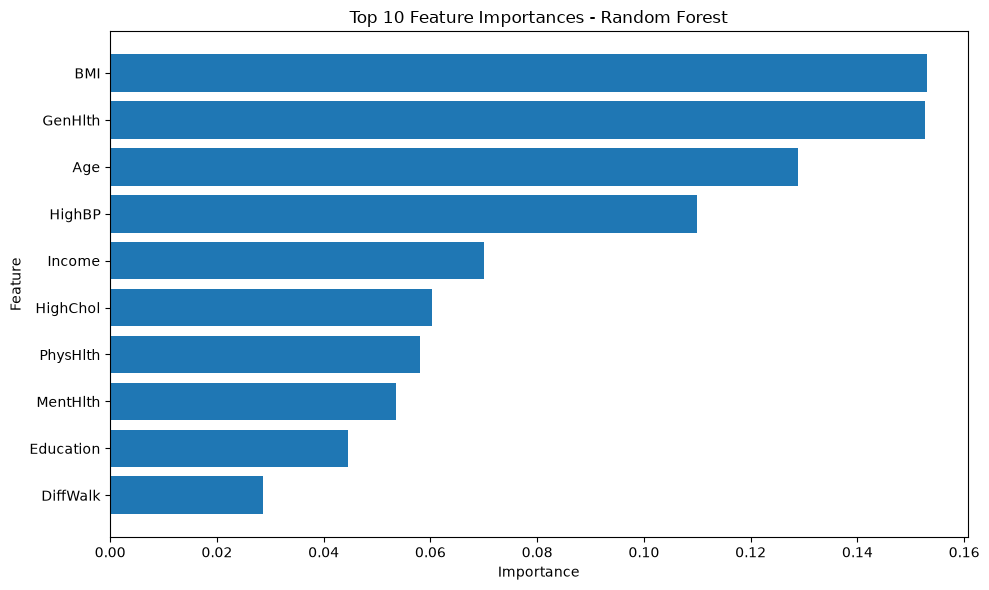

In [95]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [96]:
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [97]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_results = []

all_models = [
    ("Logistic Regression", y_pred_logistic),
    ("Balanced Logistic Regression", y_pred_logistic_balanced),
    ("Decision Tree", y_pred_tree),
    ("Random Forest", y_pred_rf),
    ("Balanced Random Forest", y_pred_rf_balanced)
]

for name, predictions in all_models:
    
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

final_results = pd.DataFrame(model_results)

final_results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.845632,0.459337,0.382500,0.391071
1,Balanced Logistic Regression,0.646582,0.444961,0.521882,0.426720
2,Decision Tree,0.845199,0.557694,0.392909,0.404761
3,Random Forest,0.849259,0.480815,0.374568,0.380432
4,Balanced Random Forest,0.681015,0.433749,0.507653,0.430111


In [98]:
final_results_percentage = final_results.copy()

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

for column in metric_columns:
    final_results_percentage[column] = (
        final_results_percentage[column] * 100
    ).round(2)

final_results_percentage

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,84.56,45.93,38.25,39.11
1,Balanced Logistic Regression,64.66,44.50,52.19,42.67
2,Decision Tree,84.52,55.77,39.29,40.48
3,Random Forest,84.93,48.08,37.46,38.04
4,Balanced Random Forest,68.10,43.37,50.77,43.01


In [99]:
diabetes_results = []

for name, predictions in all_models:
    
    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )
    
    diabetes_results.append({
        "Model": name,
        "Diabetes Precision": report["2.0"]["precision"],
        "Diabetes Recall": report["2.0"]["recall"],
        "Diabetes F1": report["2.0"]["f1-score"]
    })

diabetes_results = pd.DataFrame(diabetes_results)

diabetes_results

,Model,Diabetes Precision,Diabetes Recall,Diabetes F1
0,Logistic Regression,0.516334,0.172160,0.258222
1,Balanced Logistic Regression,0.353072,0.585373,0.440470
2,Decision Tree,0.507478,0.206394,0.293443
3,Random Forest,0.584129,0.138492,0.223899
4,Balanced Random Forest,0.327407,0.687792,0.443633


In [100]:
diabetes_results_percentage = diabetes_results.copy()

for column in [
    "Diabetes Precision",
    "Diabetes Recall",
    "Diabetes F1"
]:
    diabetes_results_percentage[column] = (
        diabetes_results_percentage[column] * 100
    ).round(2)

diabetes_results_percentage

,Model,Diabetes Precision,Diabetes Recall,Diabetes F1
0,Logistic Regression,51.63,17.22,25.82
1,Balanced Logistic Regression,35.31,58.54,44.05
2,Decision Tree,50.75,20.64,29.34
3,Random Forest,58.41,13.85,22.39
4,Balanced Random Forest,32.74,68.78,44.36


In [101]:
best_model_name = final_results.loc[
    final_results["Macro F1"].idxmax(),
    "Model"
]

print("Highest Macro F1 model:", best_model_name)

Highest Macro F1 model: Balanced Random Forest


In [102]:
final_results_percentage.to_csv(
    "final_model_comparison.csv",
    index=False
)

diabetes_results_percentage.to_csv(
    "diabetes_class_results.csv",
    index=False
)

print("Final model evaluation files saved successfully!")

Final model evaluation files saved successfully!


In [103]:
print("Best model from previous comparison:")
print(best_model_name)

Best model from previous comparison:
Balanced Random Forest


In [104]:
from sklearn.model_selection import GridSearchCV

In [105]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [106]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [107]:
grid_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [8, 12, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mo

In [108]:
print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'max_depth': 16, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [109]:
print(
    "Best cross-validation Macro F1: {:.2f}%".format(
        grid_search.best_score_ * 100
    )
)

Best cross-validation Macro F1: 44.19%


In [110]:
tuned_model = grid_search.best_estimator_

In [111]:
y_pred_tuned = tuned_model.predict(X_test)

In [112]:
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=[
            "No Diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.93      0.76      0.84     42741
 Prediabetes       0.03      0.05      0.03       926
    Diabetes       0.34      0.68      0.45      7069

    accuracy                           0.74     50736
   macro avg       0.43      0.50      0.44     50736
weighted avg       0.83      0.74      0.77     50736



In [113]:
tuned_accuracy = accuracy_score(
    y_test,
    y_pred_tuned
)

tuned_precision = precision_score(
    y_test,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

print("Accuracy      :", round(tuned_accuracy * 100, 2), "%")
print("Macro Precision:", round(tuned_precision * 100, 2), "%")
print("Macro Recall   :", round(tuned_recall * 100, 2), "%")
print("Macro F1       :", round(tuned_f1 * 100, 2), "%")

Accuracy      : 73.54 %
Macro Precision: 43.22 %
Macro Recall   : 49.64 %
Macro F1       : 44.08 %


In [114]:
print("Before tuning:")
print("Balanced Random Forest Macro F1:",
      round(rf_balanced_f1 * 100, 2), "%")

print("\nAfter tuning:")
print("Tuned Model Macro F1:",
      round(tuned_f1 * 100, 2), "%")

Before tuning:
Balanced Random Forest Macro F1: 43.01 %

After tuning:
Tuned Model Macro F1: 44.08 %


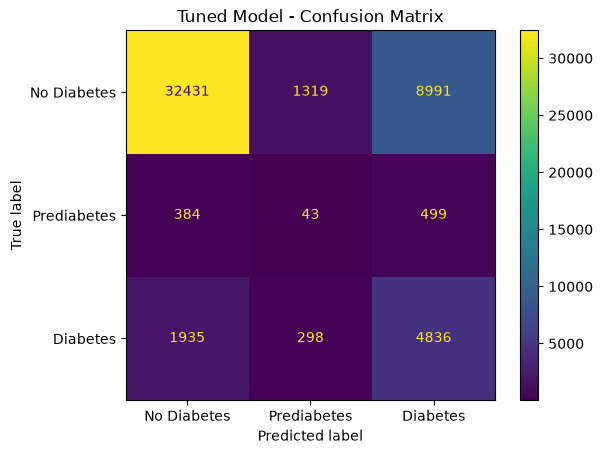

In [115]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

plt.title("Tuned Model - Confusion Matrix")
plt.show()

In [116]:
import joblib

In [117]:
joblib.dump(
    tuned_model,
    "diabetes_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [118]:
feature_information = {
    "features": features
}

joblib.dump(
    feature_information,
    "feature_information.pkl"
)

print("Feature information saved successfully!")

Feature information saved successfully!


In [119]:
loaded_model = joblib.load(
    "diabetes_model.pkl"
)

print("Model loaded successfully!")
print(loaded_model)

Model loaded successfully!
RandomForestClassifier(class_weight='balanced', max_depth=16, n_estimators=200,
                       n_jobs=-1, random_state=42)


In [120]:
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted class:", prediction[0])

Predicted class: 0.0


In [121]:
import joblib

In [122]:
joblib.dump(
    tuned_model,
    "diabetes_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [123]:
feature_information = {
    "features": features
}

joblib.dump(
    feature_information,
    "feature_information.pkl"
)

print("Feature information saved successfully!")

Feature information saved successfully!


In [124]:
loaded_model = joblib.load(
    "diabetes_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [125]:
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted class:", prediction[0])

Predicted class: 0.0
